# 3. Aprendizaje supervisado

**Pronóstico del consumo eléctrico residencial por distrito con aprendizaje automático** · Sistemas Inteligentes · Grupo 6 · UNMSM

**Objetivo.** Entrenar y comparar once modelos de regresión frente a pronósticos ingenuos, con dos formulaciones del objetivo y dos esquemas de validación; revisar el modelo adoptado (residuos, sesgo y sobreajuste) y exportarlo.

| | |
|---|---|
| **Entradas** | `datos/procesados/panel.parquet` (el grupo de k-means se recalcula con la misma semilla) |
| **Salidas** | `modelos/svr_corrida2.joblib` y `modelos/svr_corrida2.json` (modelo adoptado, entrenado con todos los distrito-meses, y sus metadatos) |

### Índice

1. [Configuración](#configuración)
2. [Partición de los datos](#partición-de-los-datos)
3. [Referencias ingenuas y métricas](#referencias-ingenuas-y-métricas)
4. [Regresión lineal: ecuación normal y gradiente descendiente](#regresión-lineal-ecuación-normal-y-gradiente-descendiente)
5. [Búsqueda de hiperparámetros y entrenamiento](#búsqueda-de-hiperparámetros-y-entrenamiento)
6. [Validación cruzada frente a prueba temporal](#validación-cruzada-frente-a-prueba-temporal)
7. [¿El mejor modelo gana de verdad? Bootstrap por distrito](#el-mejor-modelo-gana-de-verdad-bootstrap-por-distrito)
8. [Sobreajuste: entrenamiento frente a prueba](#sobreajuste-entrenamiento-frente-a-prueba)
9. [Residuos y sesgo del modelo adoptado](#residuos-y-sesgo-del-modelo-adoptado)
10. [Importancia de las variables](#importancia-de-las-variables)
11. [Modelo final, exportación y pronóstico del mes siguiente](#modelo-final-exportación-y-pronóstico-del-mes-siguiente)
12. [Verificación con el informe](#verificación-con-el-informe)
13. [Conclusiones](#conclusiones)
14. [Referencias](#referencias)

<a id="configuración"></a>

## 1. Configuración

Importaciones, estilo, versiones y semilla, panel con los rezagos y el grupo de k-means, y resultados publicados para la verificación final. El entrenamiento completo tarda unos minutos.

In [1]:
import importlib
import json
import time
import warnings

import estilo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from estilo import AQUA, BLUE, CYAN, EJE_COMA, GRIS, ICE, MESES, MUTED, NAVY, SKY, coma

from ml import config

estilo.aplicar()
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
INFORME = json.loads(config.RESULTADOS.read_text(encoding="utf8"))  # resultados publicados
RESUMEN = json.loads(config.RESUMEN_PREPROCESAMIENTO.read_text(encoding="utf8"))
INICIO = time.time()
MODULOS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scikit-learn": "sklearn",
    "scipy": "scipy",
    "xgboost": "xgboost",
    "matplotlib": "matplotlib",
}
VERSIONES = {n: importlib.import_module(m).__version__ for n, m in MODULOS.items()}
print("Semilla:", config.SEMILLA)
print(" · ".join(f"{n} {v}" for n, v in VERSIONES.items()))

from sklearn.model_selection import GridSearchCV, KFold

from ml import caracteristicas as car
from ml import modelos, pronostico
from ml.corridas import CANDIDATOS, comparar_errores, esquemas, preparar
from ml.gradiente import GDRegressor, con_intercepto, ecuacion_normal

pn, km = preparar(pd.read_parquet(config.PANEL))
d = car.supervisado(pn)
print(f"Filas supervisadas: {len(d)} ({d['PERIODO'].min()} a {d['PERIODO'].max()})")

Semilla: 42
numpy 2.4.6 · pandas 3.1.1 · scikit-learn 1.9.1 · scipy 1.17.1 · xgboost 3.2.0 · matplotlib 3.11.2


Filas supervisadas: 1638 (202502 a 202610)


<a id="partición-de-los-datos"></a>

## 2. Partición de los datos

Se usan dos esquemas, y la diferencia entre ambos es central en este trabajo:

- **A, aleatorio:** 80 % de entrenamiento y 20 % de prueba (semilla 42). Mezcla meses de 2025 y 2026 en ambas partes. Los hiperparámetros se eligen con validación cruzada de cinco particiones en el entrenamiento (Arlot y Celisse, 2010), procedimiento válido en modelos autorregresivos cuando sus errores no están correlacionados (Bergmeir et al., 2018).
- **B, temporal:** entrenamiento de febrero a diciembre de 2025 y prueba de enero a octubre de 2026, meses que el modelo nunca vio: es como se usaría el pronóstico. Con esta prueba se adopta el modelo.

In [2]:
E = esquemas(d)
pd.DataFrame(
    {
        k: {"entrenamiento": len(tr), "prueba": len(te), "meses de prueba": te["PERIODO"].nunique()}
        for k, (tr, te) in E.items()
    }
).T

,entrenamiento,prueba,meses de prueba
A,1310,328,21
B,858,780,10


<a id="referencias-ingenuas-y-métricas"></a>

## 3. Referencias ingenuas y métricas

Todo pronóstico se compara con tres referencias que no aprenden (Hyndman y Athanasopoulos, 2021): el **ingenuo** $\hat y_t = y_{t-1}$, el **estacional** $\hat y_t = y_{t-12}$ y el **estacional ajustado** $\hat y_t = y_{t-1}\,y_{t-12}/y_{t-13}$. Un modelo solo aporta si las supera.

Las métricas se calculan siempre en kWh, también en la corrida 2 (Hyndman y Koehler, 2006):

$$\mathrm{MAE} = \frac{1}{m}\sum_i |\hat y_i - y_i| \qquad \mathrm{RMSE} = \sqrt{\frac{1}{m}\sum_i (\hat y_i - y_i)^2} \qquad R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}$$

El **MAE** es la métrica principal: se lee directamente en kWh y no se deja dominar por unos pocos distritos atípicos. El $R^2$ resulta alto incluso para el ingenuo, porque los distritos van de unos 20 a más de 200 kWh; por eso no sirve para decidir.

In [3]:
pd.DataFrame({k: v["test"] for k, v in modelos.ingenuos(E["B"][1]).items()}).T

,MAE,RMSE,R2
Ingenuo (mes anterior),4.2927,6.6106,0.9768
Ingenuo estacional (mismo mes del año anterior),9.0520,11.7151,0.9272
Ingenuo estacional ajustado,3.8922,5.4438,0.9843


<a id="regresión-lineal-ecuación-normal-y-gradiente-descendiente"></a>

## 4. Regresión lineal: ecuación normal y gradiente descendiente

La regresión lineal minimiza $J(\theta) = \frac{1}{m}\lVert X\theta - y \rVert^2$. La **ecuación normal** da la solución exacta $\theta = (X^\top X)^{+} X^\top y$ (pseudoinversa, porque las variables One-Hot son colineales con el intercepto). El **gradiente descendiente**, programado en `ml/gradiente.py`, parte de $\theta = 0$ y actualiza (Bottou et al., 2018):

$$\theta \leftarrow \theta - \alpha \cdot \frac{2}{m} X^\top (X\theta - y)$$

Se prueba con tres tasas de aprendizaje en la corrida 1, esquema B. Si el gradiente está bien programado, debe llegar al mismo costo que la ecuación normal.

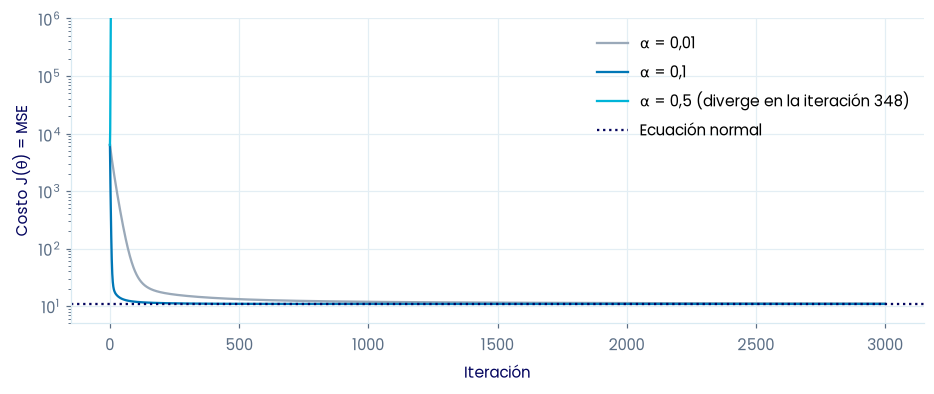

Mayor diferencia entre los parámetros del gradiente (α = 0,1) y la ecuación normal: 0.0147


In [4]:
tr, te = E["B"]
pre = modelos.preprocesador(1).fit(tr[car.entradas(1)])
A, t = pre.transform(tr[car.entradas(1)]), tr[car.objetivo(1)].values
theta = ecuacion_normal(A, t)
mse_ne = float(np.mean((con_intercepto(A) @ theta - t) ** 2))
fig, ax = plt.subplots()
for lr, col in ((0.01, GRIS), (0.1, BLUE), (0.5, CYAN)):
    gd = GDRegressor(lr=lr, epochs=3000).fit(A, t)
    costo = [
        c for c in gd.costo if c is not None and c < 1e8
    ]  # la curva que diverge se corta fuera del gráfico
    etiqueta = f"α = {coma(lr, 2 if lr < 0.1 else 1)}" + (
        f" (diverge en la iteración {len(gd.costo)})" if gd.diverge else ""
    )
    ax.plot(costo, color=col, label=etiqueta)
    if lr == 0.1:
        dif = np.max(np.abs(gd.theta - theta))
ax.axhline(mse_ne, color=NAVY, ls=":", label="Ecuación normal")
ax.set(yscale="log", ylim=(5, 1e6), xlabel="Iteración", ylabel="Costo J(θ) = MSE")
ax.legend()
plt.show()
print(
    f"Mayor diferencia entre los parámetros del gradiente (α = 0,1) y la ecuación normal: {dif:.4f}"
)

Con α = 0,01 el costo baja lentamente; con **α = 0,1** alcanza el mínimo de la ecuación normal y sus parámetros casi coinciden con los de ella, lo que verifica la implementación; con α = 0,5 el algoritmo **diverge**. La tasa de aprendizaje es un hiperparámetro decisivo.

<a id="búsqueda-de-hiperparámetros-y-entrenamiento"></a>

## 5. Búsqueda de hiperparámetros y entrenamiento

Además de la regresión lineal se entrenan Ridge (Hoerl y Kennard, 1970), Lasso (Tibshirani, 1996), árbol de decisión (Breiman et al., 1984/2017), KNN (Altman, 1992), SVR (Smola y Schölkopf, 2004), red neuronal (Rumelhart et al., 1986), Random Forest (Breiman, 2001), Gradient Boosting (Friedman, 2001) y XGBoost (Chen y Guestrin, 2016).

Cada modelo va en un `Pipeline` con el preprocesamiento (estandarización de las numéricas y One-Hot de las categóricas), de modo que el escalado se ajusta **solo** con los datos de entrenamiento de cada partición. Los hiperparámetros se eligen con `GridSearchCV`: se prueban todas las combinaciones de la rejilla con validación cruzada de cinco particiones y se elige la de menor MAE. Luego el mejor modelo se reentrena con todo el entrenamiento y se evalúa en la prueba.

In [5]:
pd.DataFrame(
    [
        {
            "modelo": k,
            "hiperparámetros": ", ".join(
                f"{modelos.nombre_parametro(p)}: {v}" for p, v in rej.items()
            ),
            "combinaciones": int(np.prod([len(v) for v in rej.values()])),
        }
        for k, (_, rej) in modelos.REJILLAS.items()
    ]
).set_index("modelo")

,hiperparámetros,combinaciones
modelo,,
Ridge,"alpha: [0.01, 0.1, 1, 10, 100]",5
Lasso,"alpha: [0.0001, 0.001, 0.01, 0.1, 1, 10]",6
Árbol de decisión,"max_depth: [3, 5, 10, None], min_samples_leaf:...",12
KNN,"n_neighbors: [3, 5, 10, 20, 40], weights: ['un...",10
SVR,"C: [0.1, 1, 10, 100], epsilon: [0.01, 0.1, 0.5]",12
Red neuronal (MLP),"hidden_layer_sizes: [(32,), (64, 32)], alpha: ...",6
Random Forest,"n_estimators: [200, 500], max_depth: [None, 10...",18
Gradient Boosting,"n_estimators: [200, 500], learning_rate: [0.03...",12
XGBoost,"n_estimators: [200, 500], learning_rate: [0.03...",16


In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=config.SEMILLA)


def lineal(f, tr, te):
    """Regresión lineal por ecuación normal y por gradiente descendiente (α = 0,1)."""
    pre = modelos.preprocesador(f).fit(tr[car.entradas(f)])
    A, B = pre.transform(tr[car.entradas(f)]), pre.transform(te[car.entradas(f)])
    t = tr[car.objetivo(f)].values
    ne = car.a_kwh(f, con_intercepto(B) @ ecuacion_normal(A, t), te)
    gd = car.a_kwh(f, GDRegressor(lr=0.1, epochs=3000).fit(A, t).predict(B), te)
    return {
        "Regresión lineal (ecuación normal)": ne,
        "Regresión lineal (gradiente descendiente)": gd,
    }


def entrenar(f, tr, te):
    """Búsqueda en rejilla con validación cruzada de 5 particiones y evaluación en la prueba."""
    X, t, y = tr[car.entradas(f)], tr[car.objetivo(f)].values, te["y"].values
    out = {k: {"pred": p, **modelos.metricas(y, p)} for k, p in lineal(f, tr, te).items()}
    for nombre, (crear, rejilla) in modelos.REJILLAS.items():
        gs = GridSearchCV(
            modelos.pipeline(f, crear()),
            rejilla,
            cv=cv,
            scoring="neg_mean_absolute_error",
            n_jobs=-1,
        )
        gs.fit(X, t)
        p = car.a_kwh(f, gs.predict(te[car.entradas(f)]), te)
        params = {modelos.nombre_parametro(k): v for k, v in gs.best_params_.items()}
        out[nombre] = {
            "pred": p,
            "modelo": gs.best_estimator_,
            "params": params,
            **modelos.metricas(y, p),
        }
    return out


res = {}
for f in (1, 2):
    for s, (tr, te) in E.items():
        t0 = time.time()
        res[(f, s)] = entrenar(f, tr, te)
        print(f"Corrida {f}, esquema {s}: {time.time() - t0:.0f} s")

Corrida 1, esquema A: 13 s


Corrida 1, esquema B: 8 s


Corrida 2, esquema A: 11 s


Corrida 2, esquema B: 11 s


In [7]:
def tabla(f, s):
    filas = {k: v["test"] for k, v in modelos.ingenuos(E[s][1]).items()}
    filas.update({k: {m: v[m] for m in ("MAE", "RMSE", "R2")} for k, v in res[(f, s)].items()})
    return pd.DataFrame(filas).T.sort_values("MAE")


print("Corrida 1 (nivel), esquema B: prueba temporal 2026")
tabla(1, "B").round(3)

Corrida 1 (nivel), esquema B: prueba temporal 2026


,MAE,RMSE,R2
Ingenuo estacional ajustado,3.8920,5.4440,0.9840
Ingenuo (mes anterior),4.2930,6.6110,0.9770
Red neuronal (MLP),4.7270,6.5130,0.9770
SVR,5.2460,7.9190,0.9670
Ridge,5.5390,7.2460,0.9720
Lasso,5.5680,7.2760,0.9720
Gradient Boosting,5.6930,7.8610,0.9670
Regresión lineal (gradiente descendiente),5.7720,7.5510,0.9700
Regresión lineal (ecuación normal),5.7730,7.5520,0.9700
XGBoost,5.9110,8.2370,0.9640


Al pronosticar el **nivel**, en la prueba temporal **ningún modelo supera al ingenuo** (4,29 kWh), aunque los $R^2$ superen 0,93: el consumo de 2026 subió y los modelos entrenados con 2025 lo subestiman.

In [8]:
print("Corrida 2 (variación mensual), esquema B: prueba temporal 2026")
tabla(2, "B").round(3)

Corrida 2 (variación mensual), esquema B: prueba temporal 2026


,MAE,RMSE,R2
SVR,3.1550,5.2150,0.9860
Random Forest,3.1930,5.1960,0.9860
KNN,3.2050,5.2170,0.9860
XGBoost,3.2650,5.3660,0.9850
Lasso,3.4320,5.3620,0.9850
Gradient Boosting,3.4450,5.6600,0.9830
Ridge,3.5550,5.5280,0.9840
Regresión lineal (gradiente descendiente),3.6430,5.5960,0.9830
Regresión lineal (ecuación normal),3.6430,5.5960,0.9830
Red neuronal (MLP),3.6910,5.7400,0.9830


Al pronosticar la **variación**, los once modelos superan al ingenuo. **SVR** obtiene el menor MAE, seguido de cerca por Random Forest, KNN y XGBoost.

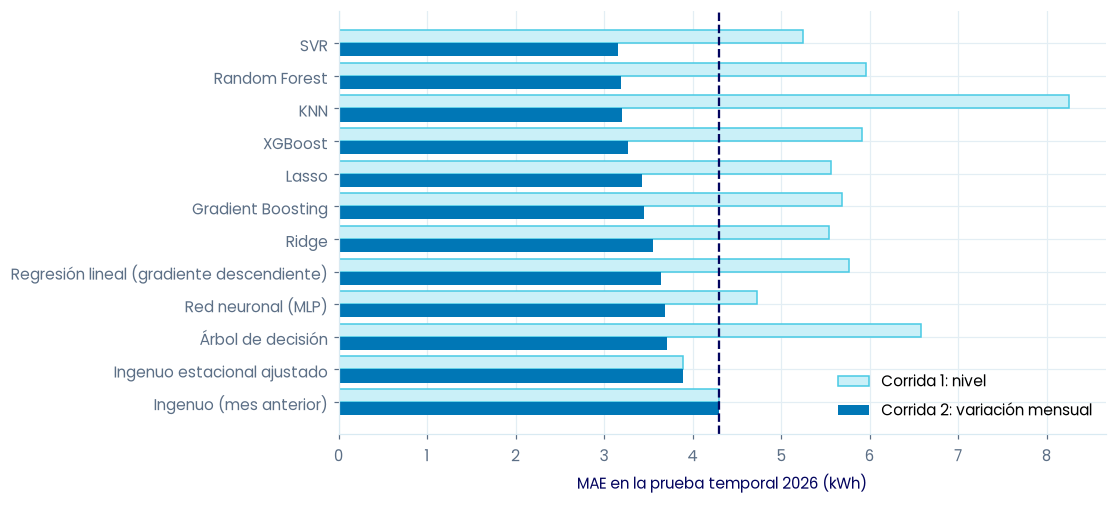

In [9]:
c1, c2 = tabla(1, "B")["MAE"], tabla(2, "B")["MAE"]
omitir = ["Ingenuo estacional (mismo mes del año anterior)", "Regresión lineal (ecuación normal)"]
orden = c2.drop(omitir).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(orden))
ax.barh(y + 0.2, c1[orden], 0.4, color=ICE, edgecolor=AQUA, label="Corrida 1: nivel")
ax.barh(y - 0.2, c2[orden], 0.4, color=BLUE, label="Corrida 2: variación mensual")
ax.axvline(c2["Ingenuo (mes anterior)"], color=NAVY, ls="--")
ax.set_yticks(y, orden)
ax.set_xlabel("MAE en la prueba temporal 2026 (kWh)")
ax.legend(loc="lower right")
plt.show()

<a id="validación-cruzada-frente-a-prueba-temporal"></a>

## 6. Validación cruzada frente a prueba temporal

¿Por qué hace falta la prueba temporal si ya hay validación cruzada? Para cada modelo, con sus hiperparámetros elegidos, se calcula el MAE en kWh de la validación cruzada de cinco particiones sobre el entrenamiento del esquema A y se compara con el MAE en la prueba aleatoria (A) y en 2026 (B).

In [10]:
def mae_cv(f, nombre, params):
    """MAE (kWh) medio y desviación en la validación cruzada del esquema A."""
    tr = E["A"][0]
    X, t = tr[car.entradas(f)], tr[car.objetivo(f)].values
    errores = []
    for i, j in cv.split(X):
        m = modelos.pipeline(f, modelos.crear(nombre, params)).fit(X.iloc[i], t[i])
        va = tr.iloc[j]
        errores.append(np.mean(np.abs(car.a_kwh(f, m.predict(X.iloc[j]), va) - va["y"].values)))
    return np.mean(errores), np.std(errores)


filas = []
for f in (1, 2):
    for nombre in CANDIDATOS:
        media, sd = mae_cv(f, nombre, res[(f, "A")][nombre]["params"])
        filas.append(
            {
                "corrida": f,
                "modelo": nombre,
                "CV (A)": media,
                "± sd": sd,
                "prueba A": res[(f, "A")][nombre]["MAE"],
                "prueba B (2026)": res[(f, "B")][nombre]["MAE"],
            }
        )
comparacion = pd.DataFrame(filas).set_index(["corrida", "modelo"])
comparacion.round(2)

CV (A)   ± sd  prueba A  prueba B (2026)
corrida modelo                                                      
1       Ridge               3.2200 0.0700    2.9600           5.5400
        Lasso               3.2100 0.0700    2.9500           5.5700
        Árbol de decisión   4.1700 0.1800    3.6200           6.5800
        KNN                 5.7500 0.2900    4.9400           8.2600
        SVR                 3.0200 0.0900    2.7500           5.2500
        Red neuronal (MLP)  3.1000 0.1200    2.7000           4.7300
        Random Forest       3.2000 0.1600    2.9300           5.9600
        Gradient Boosting   3.0500 0.1100    2.7200           5.6900
        XGBoost             2.9900 0.1000    2.7300           5.9100
2       Ridge               3.0100 0.0900    2.7500           3.5500
        Lasso               3.0300 0.0900    2.7600           3.4300
        Árbol de decisión   3.1700 0.1700    2.9600           3.7100
        KNN                 2.7200 0.0600    2.4800           3.2000
        SVR                 2.4900 0.0800    2.2700           3.1500
        Red neuronal (MLP)  2.6400 0.1200    2.3200           3.6900
        Random Forest       2.6000 0.1300    2.3500           3.1900
        Gradient Boosting   2.7600 0.1200    2.4600           3.4500
        XGBoost             2.6600 0.2300    2.4600           3.2600

En la **corrida 1**, la validación cruzada y la prueba aleatoria prometen errores de unos 3 kWh, pero en 2026 el error sube por encima del ingenuo: la división aleatoria mezcla meses de 2025 y 2026, así que el modelo «ve» el nivel de 2026 al entrenar y la validación resulta optimista. En la **corrida 2** el error de 2026 también es algo mayor (es un año distinto), pero SVR es el mejor en las tres columnas y todos superan al ingenuo. La desviación entre particiones (± sd) muestra además que algunas diferencias entre modelos cercanos son menores que la variación de la propia validación.

<a id="el-mejor-modelo-gana-de-verdad-bootstrap-por-distrito"></a>

## 7. ¿El mejor modelo gana de verdad? Bootstrap por distrito

Como se adopta el modelo de menor MAE, se estima si su ventaja puede deberse al azar con un bootstrap (Efron y Tibshirani, 1994): se remuestrean 2000 veces los 78 distritos, cada uno con sus diez meses de 2026 (los meses de un mismo distrito no son independientes), y se calcula la diferencia de MAE frente a cada modelo. Si el intervalo del 95 % incluye el cero, los modelos empatan.

In [11]:
tr, te = E["B"]
rb = res[(2, "B")]
mejor = min(CANDIDATOS, key=lambda k: rb[k]["MAE"])
err = {k: np.abs(rb[k]["pred"] - te["y"].values) for k in CANDIDATOS}
err["Ingenuo (mes anterior)"] = np.abs(te["lag1"].values - te["y"].values)
comp = pd.DataFrame(comparar_errores(err, mejor, te["UBIGEO"].values)).T.sort_values("diferencia")
empate = (comp["ic_inferior"] < 0) & (comp["ic_superior"] > 0)
comp["conclusión"] = np.where(empate, "Empate", f"{mejor} mejor")
print("Modelo adoptado:", mejor, rb[mejor]["params"])
comp.round(3)

Modelo adoptado: SVR {'C': 1, 'epsilon': 0.1}


,diferencia,ic_inferior,ic_superior,p_menor,conclusión
Ingenuo (mes anterior),-1.1380,-1.4680,-0.7890,1.0000,SVR mejor
Árbol de decisión,-0.5540,-0.7160,-0.3880,1.0000,SVR mejor
Red neuronal (MLP),-0.5360,-0.6700,-0.4090,1.0000,SVR mejor
Ridge,-0.4000,-0.5500,-0.2510,1.0000,SVR mejor
Gradient Boosting,-0.2910,-0.4780,-0.1210,1.0000,SVR mejor
Lasso,-0.2780,-0.4390,-0.1140,1.0000,SVR mejor
XGBoost,-0.1100,-0.2780,0.0370,0.9260,Empate
KNN,-0.0500,-0.1520,0.0600,0.8310,Empate
Random Forest,-0.0380,-0.1690,0.0950,0.7000,Empate


SVR es significativamente mejor que el ingenuo y que cinco modelos, pero **empata** con Random Forest, KNN y XGBoost: con diez meses de prueba, cualquiera de los cuatro daría un pronóstico de calidad equivalente. Se adoptó SVR por el criterio fijado de antemano, el menor MAE.

<a id="sobreajuste-entrenamiento-frente-a-prueba"></a>

## 8. Sobreajuste: entrenamiento frente a prueba

Un modelo que memoriza el entrenamiento tiene un error mucho menor allí que en datos nuevos. Se compara el MAE de cada modelo en su propio entrenamiento (2025) y en la prueba (2026), corrida 2.

In [12]:
filas = []
for nombre in CANDIDATOS:
    p_tr = car.a_kwh(2, rb[nombre]["modelo"].predict(tr[car.entradas(2)]), tr)
    filas.append(
        {
            "modelo": nombre,
            "MAE entrenamiento": np.mean(np.abs(p_tr - tr["y"].values)),
            "MAE prueba 2026": rb[nombre]["MAE"],
        }
    )
sobre = pd.DataFrame(filas).set_index("modelo")
razon = sobre["MAE prueba 2026"] / sobre["MAE entrenamiento"]
sobre["prueba / entrenamiento"] = razon.where(
    sobre["MAE entrenamiento"] > 1e-6
)  # KNN: error 0 en entrenamiento
sobre.sort_values("MAE prueba 2026").round(2)

,MAE entrenamiento,MAE prueba 2026,prueba / entrenamiento
modelo,,,
SVR,1.5200,3.1500,2.0800
Random Forest,1.2800,3.1900,2.5000
KNN,0.0000,3.2000,NaN
XGBoost,1.2100,3.2600,2.7000
Lasso,2.7100,3.4300,1.2700
Gradient Boosting,1.1400,3.4500,3.0300
Ridge,2.6300,3.5500,1.3500
Red neuronal (MLP),1.5100,3.6900,2.4500
Árbol de decisión,2.1700,3.7100,1.7100


KNN con pesos por distancia reproduce exactamente su entrenamiento (MAE 0, cada punto es su propio vecino), así que la razón no tiene sentido para él. Entre los demás, los ensambles de árboles (Gradient Boosting, XGBoost, Random Forest) y la red neuronal tienen las mayores brechas: memorizan parte de 2025. SVR queda en medio (su tolerancia ε y C = 1 limitan el ajuste), y los lineales y el árbol individual, que no puede crecer más allá de hojas de 10, tienen las menores, aunque con más error en 2026. Lo que decide es el error en 2026, y ahí SVR es el mejor.

<a id="residuos-y-sesgo-del-modelo-adoptado"></a>

## 9. Residuos y sesgo del modelo adoptado

En regresión, el equivalente a «calibrar» un clasificador es revisar si el modelo se equivoca **sistemáticamente** hacia un lado. Se analizan los residuos del SVR en 2026 (pronóstico − real):

- su distribución y su media (**sesgo**);
- el sesgo por mes;
- una **curva de calibración**: se ordenan los pronósticos en deciles y se compara el pronóstico medio con el consumo real medio de cada decil; si el modelo está bien calibrado, los puntos caen sobre la diagonal.

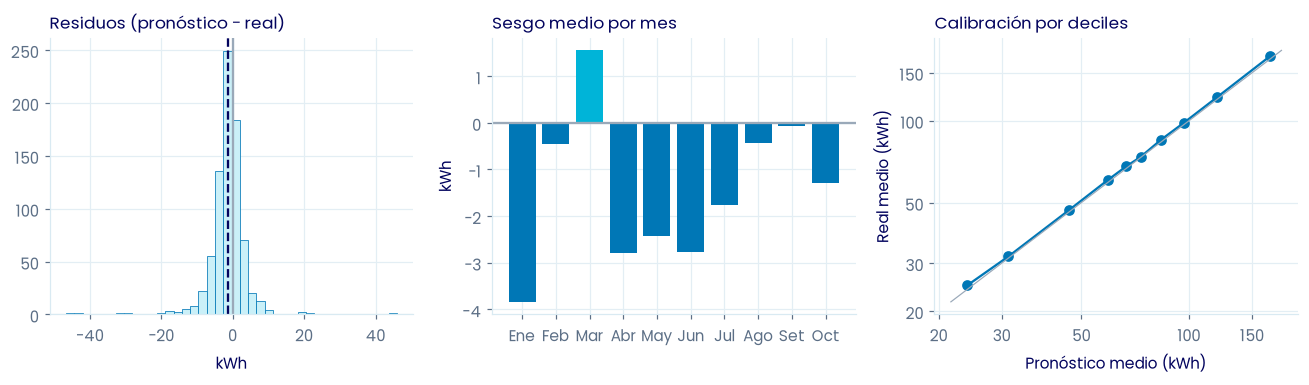

Sesgo medio: -1,43 kWh
Mediana del residuo: -1,18 kWh
Meses con sesgo negativo: 9 de 10


In [13]:
p = rb[mejor]["pred"]
t2 = te.assign(
    pred=p,
    resid=p - te["y"].values,
    abs_err=np.abs(p - te["y"].values),
    err_ing=np.abs(te["lag1"] - te["y"]),
)
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(12, 3.6))
a1.hist(t2["resid"], bins=40, color=ICE, edgecolor=BLUE, lw=0.5)
a1.axvline(0, color=GRIS)
a1.axvline(t2["resid"].mean(), color=NAVY, ls="--")
a1.set(title="Residuos (pronóstico − real)", xlabel="kWh")
mes = t2.groupby("PERIODO")["resid"].mean()
a2.bar(range(len(mes)), mes.values, color=[BLUE if v < 0 else CYAN for v in mes.values])
a2.axhline(0, color=GRIS)
a2.set_xticks(range(len(mes)), [MESES[int(m[4:]) - 1] for m in mes.index])
a2.set(title="Sesgo medio por mes", ylabel="kWh")
dec = t2.assign(decil=pd.qcut(t2["pred"], 10, labels=False)).groupby("decil")[["pred", "y"]].mean()
a3.plot(dec["pred"], dec["y"], "o-", color=BLUE)
lim = [dec.min().min() * 0.9, dec.max().max() * 1.05]
a3.plot(lim, lim, color=GRIS, lw=0.8)
a3.set(
    title="Calibración por deciles",
    xlabel="Pronóstico medio (kWh)",
    ylabel="Real medio (kWh)",
    xscale="log",
    yscale="log",
)
for eje in (a3.xaxis, a3.yaxis):
    eje.set_major_locator(plt.FixedLocator([20, 30, 50, 100, 150]))
    eje.set_major_formatter(EJE_COMA)
    eje.set_minor_locator(plt.NullLocator())
plt.tight_layout()
plt.show()
print(f"Sesgo medio: {coma(t2['resid'].mean(), 2)} kWh")
print(f"Mediana del residuo: {coma(t2['resid'].median(), 2)} kWh")
print(f"Meses con sesgo negativo: {(mes < 0).sum()} de {len(mes)}")

In [14]:
por_grupo = t2.groupby("grupo")[["err_ing", "abs_err", "resid"]].mean()
por_grupo.columns = ["MAE ingenuo", f"MAE {mejor}", "sesgo medio"]
por_grupo.round(2)

,MAE ingenuo,MAE SVR,sesgo medio
grupo,,,
1,2.0700,2.1300,-0.4800
2,3.8800,2.7000,-1.1100
3,7.5800,5.2700,-3.1500


La curva de calibración sigue la diagonal en todo el rango, pero los residuos están **desplazados hacia abajo**: el SVR tiende a quedarse por debajo del consumo real en 2026 porque el aumento de nivel de ese año no estaba en el entrenamiento (2025). No se corrige con una recalibración ajustada a 2026, porque eso usaría los datos de prueba para modificar el modelo; se declara como limitación. Por grupos, el modelo mejora al ingenuo en los grupos 2 y 3 y empata en el grupo 1, de consumo bajo; el sesgo es mayor en el grupo 3, el de mayor consumo, donde el aumento de 2026 fue más grande en kWh.

<a id="importancia-de-las-variables"></a>

## 10. Importancia de las variables

La importancia por permutación mide cuánto empeora el MAE en la prueba cuando se desordenan al azar los valores de una variable (Breiman, 2001). A diferencia de la importancia interna de los árboles, sirve para cualquier modelo, incluido el SVR.

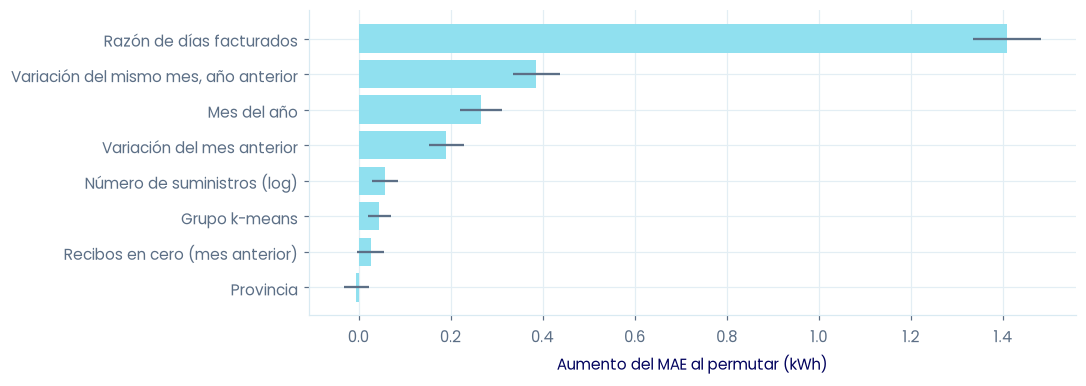

In [15]:
NOMBRES = {
    "dias_ratio": "Razón de días facturados",
    "dl_seas": "Variación del mismo mes, año anterior",
    "dl_prev": "Variación del mes anterior",
    "mes": "Mes del año",
    "p_cero_lag1": "Recibos en cero (mes anterior)",
    "grupo": "Grupo k-means",
    "log_n": "Número de suministros (log)",
    "PROV_N": "Provincia",
}
imp = (
    pd.DataFrame(modelos.importancia_permutacion(rb[mejor]["modelo"], 2, te))
    .set_index("variable")
    .rename(index=NOMBRES)
)
fig, ax = plt.subplots(figsize=(9, 3.6))
imp = imp.iloc[::-1]
ax.barh(imp.index, imp["media"], xerr=imp["sd"], color=SKY, ecolor=MUTED)
ax.set_xlabel("Aumento del MAE al permutar (kWh)")
plt.show()

La variable más influyente es la **razón de días facturados**: parte de la variación del recibo se debe a que el periodo facturado tiene más o menos días, no a cambios de hábito. Le siguen la variación del mismo mes del año anterior y el mes, que recogen la estacionalidad.

<a id="modelo-final-exportación-y-pronóstico-del-mes-siguiente"></a>

## 11. Modelo final, exportación y pronóstico del mes siguiente

Para pronosticar el mes posterior al último publicado (noviembre de 2026), el SVR se reentrena con **todos** los distrito-meses supervisados y se exporta junto con sus metadatos (hiperparámetros, datos de entrenamiento, métricas de la prueba temporal y versiones). Dos entradas de ese mes aún no se conocen: los días facturados y el número de suministros se suponen iguales a los del último mes.

In [16]:
from datetime import date

import joblib

params = rb[mejor]["params"]
final = pronostico.entrenar(d, params, nombre=mejor)
carpeta = config.RAIZ / "modelos"
carpeta.mkdir(exist_ok=True)
joblib.dump(
    {"modelo": final, "nombre": mejor, "params": params, "entradas": car.entradas(2)},
    carpeta / "svr_corrida2.joblib",
)
meta = {
    "modelo": mejor,
    "formulacion": "corrida 2: variación logarítmica; consumo = último consumo × exp(pronóstico)",
    "hiperparametros": params,
    "entradas": car.entradas(2),
    "entrenamiento_final": {
        "filas": len(d),
        "desde": d["PERIODO"].min(),
        "hasta": d["PERIODO"].max(),
    },
    "prueba_temporal_2026": {k: round(float(rb[mejor][k]), 4) for k in ("MAE", "RMSE", "R2")},
    "ingenuo_2026": {
        k: round(float(v), 4)
        for k, v in modelos.ingenuos(te)["Ingenuo (mes anterior)"]["test"].items()
    },
    "sesgo_medio_2026_kwh": round(float(t2["resid"].mean()), 4),
    "semilla": config.SEMILLA,
    "versiones": VERSIONES,
    "fecha": date.today().isoformat(),
}
(carpeta / "svr_corrida2.json").write_text(
    json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf8"
)
sig = pd.DataFrame(
    [x.__dict__ for x in pronostico.pronosticar(final, pronostico.filas_siguiente(pn))]
)
sig = sig.merge(
    pn.drop_duplicates("UBIGEO")[["UBIGEO", "DIST_N"]], left_on="ubigeo", right_on="UBIGEO"
)
cols = ["DIST_N", "periodo", "ultimo_consumo", "consumo", "variacion"]
pd.concat([sig.nlargest(5, "variacion")[cols], sig.nsmallest(5, "variacion")[cols]])

,DIST_N,periodo,ultimo_consumo,consumo,variacion
30,CHALACO,202611,25.7872,29.3593,0.1385
18,SICCHEZ,202611,32.0234,36.4475,0.1382
7,LAS LOMAS,202611,74.7215,81.0040,0.0841
14,MONTERO,202611,37.7125,40.7674,0.0810
10,AYABACA,202611,34.2132,36.6277,0.0706
56,LOBITOS,202611,146.3072,143.2539,-0.0209
24,LALAQUIZ,202611,23.3784,23.0283,-0.0150
41,COLAN,202611,99.0990,98.3554,-0.0075
37,YAMANGO,202611,28.0025,27.8115,-0.0068
72,CASITAS,202611,70.5999,70.1823,-0.0059


<a id="verificación-con-el-informe"></a>

## 12. Verificación con el informe

In [17]:
for f in (1, 2):
    for s in ("A", "B"):
        for k, v in res[(f, s)].items():
            assert abs(v["MAE"] - INFORME[f"c{f}{s}"][k]["test"]["MAE"]) < 1e-9, (f, s, k)
            if "params" in v:
                assert json.loads(json.dumps(v["params"])) == INFORME[f"c{f}{s}"][k]["params"], (
                    f,
                    s,
                    k,
                )
assert mejor == INFORME["mejor"]
for k, v in comp.iterrows():
    assert abs(v["diferencia"] - INFORME["comparacion_adoptado"][k]["diferencia"]) < 1e-9
print("Métricas, hiperparámetros, modelo adoptado y bootstrap coinciden con el informe.")

print(f"Tiempo de ejecución del notebook: {time.time() - INICIO:.0f} s")

Métricas, hiperparámetros, modelo adoptado y bootstrap coinciden con el informe.
Tiempo de ejecución del notebook: 63 s


<a id="conclusiones"></a>

## 13. Conclusiones

- La **formulación del objetivo** fue decisiva: pronosticando el nivel, ningún modelo supera al ingenuo en 2026; pronosticando la variación mensual, los once lo superan.
- La validación con división aleatoria fue **optimista** en la corrida 1; la prueba temporal es la que refleja el uso real del pronóstico.
- **SVR** (núcleo RBF, C = 1, ε = 0,1) obtiene un MAE de **3,15 kWh**, 26,5 % menos que el ingenuo; empata estadísticamente con Random Forest, KNN y XGBoost y sobreajusta menos que los ensambles de árboles.
- El modelo está bien calibrado en orden (curva por deciles sobre la diagonal) pero tiene un **sesgo negativo** en 2026 por el cambio de nivel de ese año.
- El gradiente descendiente programado alcanza la solución de la ecuación normal con α = 0,1 y diverge con α = 0,5.
- El modelo final y sus metadatos quedan en `modelos/`; la API lo reentrena al arrancar con los mismos hiperparámetros.

<a id="referencias"></a>

## 14. Referencias

- Altman, N. S. (1992). An introduction to kernel and nearest-neighbor nonparametric regression. *The American Statistician, 46*(3), 175–185. https://doi.org/10.1080/00031305.1992.10475879
- Arlot, S. y Celisse, A. (2010). A survey of cross-validation procedures for model selection. *Statistics Surveys, 4*, 40–79. https://doi.org/10.1214/09-SS054
- Bergmeir, C., Hyndman, R. J. y Koo, B. (2018). A note on the validity of cross-validation for evaluating autoregressive time series prediction. *Computational Statistics & Data Analysis, 120*, 70–83. https://doi.org/10.1016/j.csda.2017.11.003
- Bottou, L., Curtis, F. E. y Nocedal, J. (2018). Optimization methods for large-scale machine learning. *SIAM Review, 60*(2), 223–311. https://doi.org/10.1137/16M1080173
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Breiman, L., Friedman, J. H., Olshen, R. A. y Stone, C. J. (2017). *Classification and regression trees*. Routledge. https://doi.org/10.1201/9781315139470 (Trabajo original publicado en 1984)
- Chen, T. y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). ACM. https://doi.org/10.1145/2939672.2939785
- Efron, B. y Tibshirani, R. J. (1994). *An introduction to the bootstrap*. Chapman and Hall/CRC. https://doi.org/10.1201/9780429246593
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Hoerl, A. E. y Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634
- Hyndman, R. J. y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/
- Hyndman, R. J. y Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting, 22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001
- Rumelhart, D. E., Hinton, G. E. y Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature, 323*(6088), 533–536. https://doi.org/10.1038/323533a0
- Smola, A. J. y Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing, 14*(3), 199–222. https://doi.org/10.1023/B:STCO.0000035301.49549.88
- Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B (Methodological), 58*(1), 267–288. https://doi.org/10.1111/j.2517-6161.1996.tb02080.x